In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1)

In [2]:
movies_raw = pd.read_csv('../data/movies/movies.csv')
genre_groups_raw = pd.read_csv('../data/movies/genre_groups.csv')
print(movies_raw.shape)
print(genre_groups_raw.shape)

(3201, 16)
(12, 2)


In [3]:
movies_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   float64
 15

In [4]:
genre_groups_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Major Genre  12 non-null     str  
 1   Genre group  12 non-null     str  
dtypes: str(2)
memory usage: 324.0 bytes


In [5]:
movies_raw.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


In [6]:
genre_groups_raw.head()

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music


One row is one movie.

All columns will be used (unless we decide otherwise later)

## 2)

In [7]:
movies_raw['Release Date'].value_counts()

Release Date
Oct 11 2002    9
Sep 16 2005    8
Dec 31 1969    8
Apr 28 2006    8
Sep 30 2005    7
              ..
May 01 2009    1
Dec 17 2008    1
Aug 09 2006    1
Oct 31 2008    1
Jul 17 1998    1
Name: count, Length: 1600, dtype: int64

In [8]:
movies_raw = pd.read_csv('../data/movies/movies.csv',  parse_dates=['Release Date'])

In [9]:
movies = movies_raw.copy()
genre_groups = genre_groups_raw.copy()

In [10]:
print(movies['Release Date'].isna().sum())
print(movies['Release Date'].describe())

0
count                          3201
mean     1998-12-06 23:41:06.354264
min             1928-12-31 00:00:00
25%             1996-09-20 00:00:00
50%             2001-12-14 00:00:00
75%             2005-12-16 00:00:00
max             2046-12-31 00:00:00
Name: Release Date, dtype: object


In [11]:
print(movies.Title.duplicated().sum())

24


In [12]:
print(movies[movies.Title.duplicated(keep=False)].sort_values(by='Title'))

                             Title     US Gross  Worldwide Gross  \
25    20,000 Leagues Under the Sea   28200000.0     2.820000e+07   
26    20,000 Leagues Under the Sea    8000000.0     8.000000e+06   
2406     A Nightmare on Elm Street   63075011.0     1.051750e+08   
654      A Nightmare on Elm Street   25504513.0     2.550451e+07   
48             Alice in Wonderland          0.0     0.000000e+00   
1138           Alice in Wonderland  334191110.0     1.023291e+09   
67     Around the World in 80 Days   42000000.0     4.200000e+07   
1238   Around the World in 80 Days   24004159.0     7.200416e+07   
85                         Ben-Hur    9000000.0     9.000000e+06   
86                         Ben-Hur   73000000.0     7.300000e+07   
2064                 Casino Royale  167365000.0     5.963650e+08   
159                  Casino Royale   22744718.0     4.174472e+07   
1514                         Crash   54557348.0     9.838711e+07   
1505                         Crash    3357324.0 

In [13]:
movies['Release Date'].describe()

count                          3201
mean     1998-12-06 23:41:06.354264
min             1928-12-31 00:00:00
25%             1996-09-20 00:00:00
50%             2001-12-14 00:00:00
75%             2005-12-16 00:00:00
max             2046-12-31 00:00:00
Name: Release Date, dtype: object

In [14]:
movies[movies['Release Date'] > pd.to_datetime('2026-11-24')].sort_values(by='Release Date')

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1028,Wings,NaN,NaN,NaN,2000000.0,2027-08-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,7.9,3035.0
822,She Done Him Wrong,2000000.0,2000000.0,NaN,200000.0,2033-02-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,6.7,1795.0
33,42nd Street,2300000.0,2300000.0,NaN,439000.0,2033-03-09,NaN,NaN,Warner Bros.,Based on Book/Short Story,Musical,NaN,NaN,95.0,7.7,4263.0
495,King Kong (1933),10000000.0,10000000.0,NaN,670000.0,2033-04-07,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,Modern Times,163245.0,163245.0,NaN,1500000.0,2036-02-05,NaN,NaN,Kino International,NaN,Comedy,NaN,NaN,100.0,8.5,35773.0
174,"Charge of the Light Brigade, The",0.0,0.0,NaN,1200000.0,2036-10-20,NaN,NaN,Warner Bros.,Based on Real Life Events,Action,Dramatization,Michael Curtiz,NaN,NaN,NaN
924,Snow White and the Seven Dwarfs,184925485.0,184925485.0,NaN,1488000.0,2037-12-21,NaN,NaN,Walt Disney Pictures,Traditional/Legend/Fairytale,Musical,Fantasy,NaN,97.0,7.8,38141.0
1045,The Wizard of Oz,28202232.0,28202232.0,NaN,2777000.0,2039-08-25,G,103.0,Warner Bros.,Based on Book/Short Story,Musical,Fantasy,King Vidor,NaN,8.3,102795.0
400,Gone with the Wind,198680470.0,390525192.0,NaN,3900000.0,2039-12-15,G,222.0,MGM,Based on Book/Short Story,Drama,Historical Fiction,George Cukor,97.0,8.2,78947.0
337,Fantasia,83320000.0,83320000.0,NaN,2280000.0,2040-11-13,NaN,NaN,Walt Disney Pictures,Compilation,Musical,Multiple Creative Types,NaN,98.0,7.8,29914.0


In [15]:
print(movies[movies['Release Date'] > pd.to_datetime('2026-11-24')]['Release Date'].count())

16


In [16]:
print(movies[(movies['Release Date'] > pd.to_datetime('2026-11-24')) & ((movies['Worldwide Gross'] > 0) == False)])

                                 Title  US Gross  Worldwide Gross  \
174   Charge of the Light Brigade, The       0.0              0.0   
412            How Green Was My Valley       0.0              0.0   
1028                             Wings       NaN              NaN   

      US DVD Sales  Production Budget Release Date MPAA Rating  \
174            NaN          1200000.0   2036-10-20         NaN   
412            NaN          1250000.0   2041-10-28         NaN   
1028           NaN          2000000.0   2027-08-12         NaN   

      Running Time min       Distributor                     Source  \
174                NaN      Warner Bros.  Based on Real Life Events   
412                NaN  20th Century Fox  Based on Book/Short Story   
1028               NaN               NaN                        NaN   

     Major Genre  Creative Type        Director  Rotten Tomatoes Rating  \
174       Action  Dramatization  Michael Curtiz                     NaN   
412          NaN       

In [17]:
movies[movies.Title == 'Wings']

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1028,Wings,NaN,NaN,NaN,2000000.0,2027-08-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,7.9,3035.0


In [18]:
movies['Release Date'] = movies['Release Date'].apply(lambda x: x + pd.offsets.DateOffset(years = -100) if x > pd.to_datetime('2026-11-24') else x)

In [19]:
movies[movies.Title == 'Wings']

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1028,Wings,NaN,NaN,NaN,2000000.0,1927-08-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,7.9,3035.0


In [20]:
print(movies[movies['Release Date'] > pd.to_datetime('2026-11-24')]['Release Date'].count())

0


In [21]:
print(movies[movies['Release Date'] > pd.to_datetime('2011-01-01')][['Title', 'Release Date', 'Director', 'Worldwide Gross']])

                                                Title Release Date  \
15                     Over the Hill to the Poorhouse   2020-09-17   
26                       20,000 Leagues Under the Sea   2016-12-24   
85                                            Ben-Hur   2025-12-30   
102                                    The Big Parade   2025-01-01   
120                             The Birth of a Nation   2015-02-08   
467                                       Intolerance   2016-09-05   
2658                                         Restless   2011-01-28   
2967  The Adventures of Tintin: Secret of the Unicorn   2011-12-23   

              Director  Worldwide Gross  
15                 NaN        3000000.0  
26                 NaN        8000000.0  
85                 NaN        9000000.0  
102         King Vidor       22000000.0  
120                NaN       11000000.0  
467                NaN              NaN  
2658               NaN              0.0  
2967  Steven Spielberg           

Restless if from 2011 not 1911. The adventures of Tintin was released both in 1911 and 2011, but considering the director is Steven Spielberg, we can safely assume this is the 2011 version. Movies after 2011 seem to all have 100 years added to their release date (error)

In [22]:
movies['Release Date'] = movies['Release Date'].apply(lambda x: x + pd.offsets.DateOffset(years = -100) if x > pd.to_datetime('2012-01-01') else x)

In [23]:
print(movies[movies['Release Date'] > pd.to_datetime('2011-01-01')][['Title', 'Release Date']])

                                                Title Release Date
2658                                         Restless   2011-01-28
2967  The Adventures of Tintin: Secret of the Unicorn   2011-12-23


Problems:
* Release Date loaded as string, not a date. Solution: reloaded it as dates
* 24 movie titles exist twice. Some are remakes, others are potentially duplicates, but we don't know, the imdb ratings are duplicated for all 24 regardless if it's a remake or not. Solution: We leave these 24 as is for now as each duplicate has at least some columns which aren't duplicate data and dropping them would lose data.
* 16 movies have a 'release date' in the future. 13 of them already have gross, so clearly mistake in the 'Release Date' Out of the other 3, 2 of them have Production budget set even though they are 10 years in the future or more, that seems like they are also mistakes in terms of 'Release Date'. As for the 16th, it's release date is less than a year into the future so it could have been a correct 'Release Date'. Double-checking on imdb, it turns out each of these 16 movies were released 100 years earlier than their date says. Further investigation shows that the movie Restless does appear to be from 2011, but movies after it seem to be from 100 years earlier. Solution: subtract 100 years from the release date where appropriate (22 movies total).

## 3)

### Missing title:

In [24]:
movies[movies.Title.isna()]

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
3053,NaN,26403.0,3080493.0,NaN,3700000.0,2006-11-03,Not Rated,85.0,IFC Films,Original Screenplay,Thriller/Suspense,Contemporary Fiction,NaN,39.0,6.6,11986.0


After a bit of searching for movies that matches above values for 'Release Date', 'Distributor', 'Genre', 'Running Time',... the above movies looks to be titled 'Unknown', which with a bit of imagination could explain why the Title all of a sudden is NaN in our data. Let's fix it.

In [25]:
movies.loc[movies.Title.isna(), 'Title'] = 'Unknown'

In [26]:
print(movies[movies.Title.isna()]['Title'].count())
movies[(movies['Release Date'] == '2006-11-03') & (movies.Distributor == 'IFC Films')]

0


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
3053,Unknown,26403.0,3080493.0,NaN,3700000.0,2006-11-03,Not Rated,85.0,IFC Films,Original Screenplay,Thriller/Suspense,Contemporary Fiction,NaN,39.0,6.6,11986.0


### Worldwide gross/US Gross:

In [27]:
movies[movies['Worldwide Gross'].isna()]

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
118,Bananas,NaN,NaN,NaN,2000000.0,1971-04-28,PG-13,NaN,MGM,Original Screenplay,Comedy,NaN,Woody Allen,89.0,7.1,12415.0
254,Damnation Alley,NaN,NaN,NaN,17000000.0,1977-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.7,1655.0
266,Death Race 2000,NaN,NaN,NaN,300000.0,1975-04-01,R,NaN,NaN,Based on Book/Short Story,NaN,Science Fiction,NaN,84.0,6.1,10015.0
404,Hell's Angels,NaN,NaN,NaN,4000000.0,1929-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.0,7.9,2050.0
467,Intolerance,NaN,NaN,NaN,385907.0,1916-09-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,NaN,NaN
1025,Waterloo,NaN,NaN,NaN,25000000.0,1970-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1028,Wings,NaN,NaN,NaN,2000000.0,1927-08-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.0,7.9,3035.0


We might be able to find these values in other data if we looked hard enoug, but then we'd have to verify that it was calculated the same way as for other movies. Doable, but a bit too much work for now. Let's just leave these values as NaN for now.

### US DVD Sales:

Many missing values. Let's check if 'US DVD Sales' missing values move with 'Release Date'.

In [28]:
movies[movies['US DVD Sales'].isna()]['Release Date'].describe()

count                          2637
mean     1996-05-06 13:41:50.580204
min             1915-02-08 00:00:00
25%             1994-10-14 00:00:00
50%             2000-05-05 00:00:00
75%             2003-10-17 00:00:00
max             2011-12-23 00:00:00
Name: Release Date, dtype: object

In [29]:
movies[movies['US DVD Sales'].notna()]['Release Date'].describe()

count                           564
mean     2007-02-13 21:37:01.276595
min             1945-12-31 00:00:00
25%             2006-08-11 00:00:00
50%             2007-09-17 12:00:00
75%             2008-12-05 00:00:00
max             2010-05-28 00:00:00
Name: Release Date, dtype: object

There are both older and newer movies with missing 'US DVD Sales' and both older and newer that have 'US DVD Sales'. There are way too many missing values to fill in by hand and there could also be good reason why many movies are missing values. So we'll just leave the values as is.

## Production budget

In [30]:
movies[movies['Production Budget'].isna()]

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1271,Baby Mama,60494212.0,64391484.0,24304275.0,NaN,2008-04-25,PG-13,99.0,Universal,Original Screenplay,Comedy,Contemporary Fiction,NaN,63.0,6.1,16128.0


A quick lookup, shows this movie had a production budget of $30 million. Let's fix it.

In [31]:
movies.loc[movies.Title == 'Baby Mama']

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1271,Baby Mama,60494212.0,64391484.0,24304275.0,NaN,2008-04-25,PG-13,99.0,Universal,Original Screenplay,Comedy,Contemporary Fiction,NaN,63.0,6.1,16128.0


In [32]:
movies.loc[movies.Title == 'Baby Mama', 'Production Budget'] = 30000000

In [33]:
print(movies.loc[movies.Title == 'Baby Mama']['Production Budget'])
print(movies[movies['Production Budget'].isna()]['Production Budget'].count())

1271    30000000.0
Name: Production Budget, dtype: float64
0


In [34]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Title                   3201 non-null   str           
 1   US Gross                3194 non-null   float64       
 2   Worldwide Gross         3194 non-null   float64       
 3   US DVD Sales            564 non-null    float64       
 4   Production Budget       3201 non-null   float64       
 5   Release Date            3201 non-null   datetime64[us]
 6   MPAA Rating             2596 non-null   str           
 7   Running Time min        1209 non-null   float64       
 8   Distributor             2969 non-null   str           
 9   Source                  2836 non-null   str           
 10  Major Genre             2926 non-null   str           
 11  Creative Type           2755 non-null   str           
 12  Director                1870 non-null   str           
 13 

We have fixed some columns with real existing values from other sources, it is likely other columns also have real existing values (that we just don't have access to in our data). A more time effecient fix would be to find actual reliable data for all these missing values (we will not do this for this exercise), so until we do that, it is better to leave these values as NaN.

## 4)

In [35]:
movies['Major Genre'].value_counts().sort_index()

Major Genre
Action                 420
Adventure              274
Black Comedy            36
Comedy                 675
Concert/Performance      5
Documentary             43
Drama                  789
Horror                 219
Musical                 53
Romantic Comedy        137
Thriller/Suspense      239
Western                 36
Name: count, dtype: int64

In [36]:
genre_groups.sort_values('Major Genre')

,Major Genre,Genre group
5,Action,Action & adventure
6,Adventure,Action & adventure
3,Black Comedy,Comedy & music
1,Comedy,Comedy & music
11,Concert/Performance,Non-fiction
10,Documentary,Non-fiction
0,Drama,Drama
9,Horror,Thriller & horror
4,Musical,Comedy & music
2,Romantic Comedy,Comedy & music


In [37]:
movies.shape

(3201, 16)

In [38]:
movies = movies.merge(genre_groups, on='Major Genre', how='left')

In [39]:
movies.shape

(3201, 17)

In [40]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Title                   3201 non-null   str           
 1   US Gross                3194 non-null   float64       
 2   Worldwide Gross         3194 non-null   float64       
 3   US DVD Sales            564 non-null    float64       
 4   Production Budget       3201 non-null   float64       
 5   Release Date            3201 non-null   datetime64[us]
 6   MPAA Rating             2596 non-null   str           
 7   Running Time min        1209 non-null   float64       
 8   Distributor             2969 non-null   str           
 9   Source                  2836 non-null   str           
 10  Major Genre             2926 non-null   str           
 11  Creative Type           2755 non-null   str           
 12  Director                1870 non-null   str           
 13 

In [41]:
movies.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes,Genre group
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,1998-06-12,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0,NaN
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,1998-08-07,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0,Drama
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,1998-08-28,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0,Comedy & music
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,1998-09-11,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN,Comedy & music
4,Slam,1009819.0,1087521.0,NaN,1000000.0,1998-10-09,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0,Drama


## 5)

questions to start from:
1) Do films with a big budget earn more?
2) Do critics and audiences agree?
3) How do the genres differ, in ratings and in money?
4) Which columns are almost empty, and what does that do to your answers?

In [42]:
movies['Gross_per_Budget'] = movies['Worldwide Gross'] / movies ['Production Budget']

In [44]:
movies['Has_Non_US_Gross'] = movies['US Gross'] < movies['Worldwide Gross']

In [45]:
movies.Has_Non_US_Gross.value_counts(dropna=False)

Has_Non_US_Gross
True     1922
False    1279
Name: count, dtype: int64

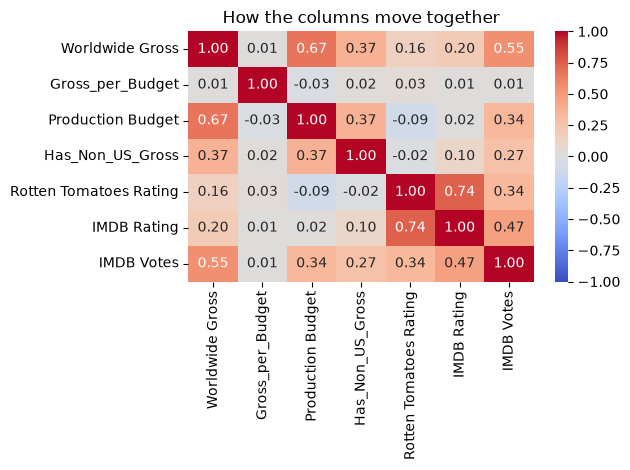

In [49]:
columns = ['Worldwide Gross', 'Gross_per_Budget', 'Production Budget', 'Has_Non_US_Gross', 'Rotten Tomatoes Rating', 'IMDB Rating', 'IMDB Votes']
corr = movies[columns].corr()
fig, ax = plt.subplots()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('How the columns move together')
plt.tight_layout()
plt.show()

## 6)

In [99]:
movies.groupby('Major Genre').apply(lambda x: pd.Series(dict(
    number_of_movies=x['Title'].count(),
    average_tomatoes_rating=x['Rotten Tomatoes Rating'].mean().round(1),
    average_imdb_rating=x['IMDB Rating'].mean().round(1),
    average_Gross_per_Budget=x['Gross_per_Budget'].mean().round(1),
    average_Budget_in_millions=(x['Production Budget']/1000000).mean().round(1)
    ))).sort_values('average_Budget_in_millions')

,number_of_movies,average_tomatoes_rating,average_imdb_rating,average_Gross_per_Budget,average_Budget_in_millions
Major Genre,,,,,
Documentary,43.0,81.1,7.0,144.0,4.2
Concert/Performance,5.0,66.7,6.3,6.5,6.1
Black Comedy,36.0,58.6,6.8,2.4,12.8
Horror,219.0,41.2,5.7,69.6,18.5
Musical,53.0,68.0,6.4,10.0,21.4
Drama,789.0,63.1,6.8,4.6,22.6
Western,36.0,65.0,6.8,2.9,25.1
Comedy,675.0,47.8,5.9,4.1,28.4
Romantic Comedy,137.0,43.0,5.9,4.4,28.4


In [98]:
movies.groupby('Genre group').apply(lambda x: pd.Series(dict(
    number_of_movies=x['Title'].count(),
    average_tomatoes_rating=x['Rotten Tomatoes Rating'].mean().round(1),
    average_imdb_rating=x['IMDB Rating'].mean().round(1),
    average_Gross_per_Budget=x['Gross_per_Budget'].mean().round(1),
    average_Budget_in_millions=(x['Production Budget']/1000000).mean().round(1)
    ))).sort_values('average_Budget_in_millions')

,number_of_movies,average_tomatoes_rating,average_imdb_rating,average_Gross_per_Budget,average_Budget_in_millions
Genre group,,,,,
Non-fiction,48.0,79.3,6.9,129.7,4.4
Drama,789.0,63.1,6.8,4.6,22.6
Thriller & horror,458.0,44.8,6.0,35.1,26.1
Comedy & music,901.0,48.5,5.9,4.5,27.4
Action & adventure,730.0,52.8,6.2,4.7,58.5


In [64]:
movies['Production Budget'].describe()

count    3.201000e+03
mean     3.106884e+07
std      3.558036e+07
min      2.180000e+02
25%      6.600000e+06
50%      2.000000e+07
75%      4.200000e+07
max      3.000000e+08
Name: Production Budget, dtype: float64

In [69]:
budget_groups = pd.qcut(
    movies['Production Budget'],
    4,
    labels=['< 6.6 mil', '6.6 - 20 mil', '20 - 42 mil', '> 42 mil']
)
movies['Gross_per_Budget'].groupby(budget_groups).agg(
    ['count', 'mean']
).round(2)

,count,mean
Production Budget,,
< 6.6 mil,796,37.78
6.6 - 20 mil,917,3.46
20 - 42 mil,689,2.48
> 42 mil,792,2.46


## 7)

In [91]:
q1 = movies['Production Budget'].quantile(0.25)
q3 = movies['Production Budget'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
lower = q1 - 1.5 * (q3 - q1)
print(upper, lower)

95100000.0 -46500000.0


In [101]:
median = movies['Production Budget'].median()
mean = movies['Production Budget'].mean()
print(round(median/1000000, 2), round(mean/1000000, 2))

20.0 31.07


The mean and the median together says more than any of them seperate. If we are intrested in the median specifically than the median obviously says more and if we are interested in the mean value then the mean says more. One could ask themselves if the mean or the median is more sensitive to a few data points and in our case the mean is more sensitive for a few extreme values, but doesn't make it less true or less valuable as a measurement, it just means that you can't look at the mean and expect the median to be the same as the mean.

## 8)

In [92]:
sns.set_style("darkgrid", {
    "axes.facecolor": "#C4ADE6",
    "grid.color": "#404040",
    "grid.linewidth": 0.8,    
})

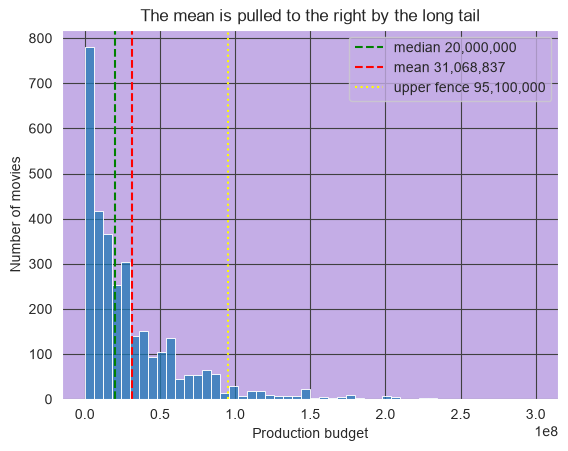

In [ ]:
fig, ax = plt.subplots()
sns.histplot(data=movies, x='Production Budget', bins=50, ax=ax)
ax.axvline(median, color='green', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='yellow', linestyle=':', label=f'upper fence {upper:,.0f}')
ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('Production budget')
ax.set_ylabel('Number of movies')
ax.legend()
plt.show()

In [94]:
movies['budget_outlier'] = movies['Production Budget'] > upper

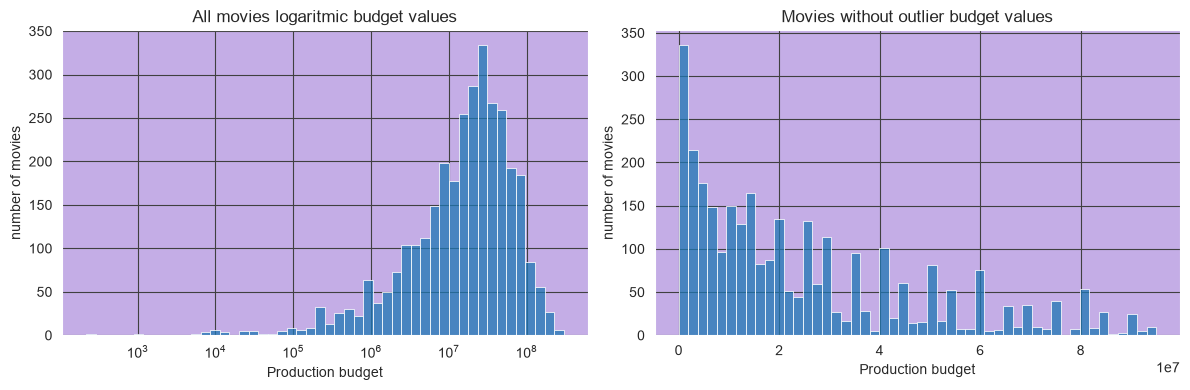

In [102]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].set_xscale(value='log')
sns.histplot(data=movies, x='Production Budget', bins=50, ax=axes[0])
sns.histplot(data=movies[~movies.budget_outlier],x='Production Budget', bins=50, ax=axes[1])
axes[0].set_title('All movies logaritmic budget values')
axes[1].set_title('Movies without outlier budget values')

for ax in axes:
    ax.set_xlabel('Production budget')
    ax.set_ylabel('number of movies')
plt.tight_layout()
plt.show()

## 9)